<a href="https://colab.research.google.com/github/ST10286777/DASC_A2_Q7/blob/main/Q7_DeepSeekGenerated.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# ---------------------------------------------------------
# OPTION A: Upload the CSV file directly from your computer
# ---------------------------------------------------------
from google.colab import files
import io
import pandas as pd

# This will open a file picker dialog in your browser.
uploaded = files.upload()          # Select School_Data_CSV.csv

# 'uploaded' is a dict {filename: bytes}. We grab the first file.
filename = next(iter(uploaded))

# Read bytes straight into a DataFrame using 'latin1' encoding to handle special characters
df = pd.read_csv(io.BytesIO(uploaded[filename]), encoding='latin1')

print(f"Loaded '{filename}' with shape {df.shape}")
df.head()

Saving School_Data_CSV.csv to School_Data_CSV (1).csv
Loaded 'School_Data_CSV (1).csv' with shape (199853, 9)


/tmp/ipykernel_4493/4049262636.py:15: DtypeWarning: Columns (0,7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(io.BytesIO(uploaded[filename]), encoding='latin1')


,emisno,centername,institution_name,centreno,quintile,ward_id,street_address,new_long,new_lat
0,200100005,ABERDEEN SECONDARY SCHOOL (20),ABERDEEN SECONDARY SCHOOL,4201001,3,21001001,"10 PARLIAMENT STREET, ABERDEEN, 6270",24.06183,-32.47385
1,200100012,ADELAIDE GYMNASIUM,ADELAIDE GYMNASIUM,4171044,4,21208001,"WELSH STREET, ADELAIDE, 5760",26.29476,-32.71036
2,200100018,AEROVILLE(SOMERSET EAST) (20),AEROVILLE SECONDARY SCHOOL,4201002,3,21002002,"PERSEVERANCE DR, SOMERSET EAST, 5850",25.60073,-32.74592
3,200100019,Al Azhar Institute,AL-AZHAR PRIMARY SCHOOL,4222001,NOT APPLICABLE,29500009,"42 RUDOLPH STREET, MALABAR, PORT ELIZABETH, 6000",25.53563,-33.91924
4,200100021,ALEXANDER ROAD HIGH SCHOOL,ALEXANDER ROAD HIGH SCHOOL,4221002,5,29300007,"ALEXANDER ROAD, NEWTON PARK, PORT ELIZABETH, 6055",25.57181,-33.94147


In [6]:
# ---------------------------------------------------------------
# 2. DATA CLEANING PIPELINE
# ---------------------------------------------------------------
import numpy as np
import pandas as pd

# Make a working copy so the raw df remains intact for reference
df_clean = df.copy()

# ---- 2.1 Strip whitespace from column names --------------------
df_clean.columns = df_clean.columns.str.strip().str.lower()

# ---- 2.2 Replace obvious 'missing' string tokens with NaN -------
# The dataset uses 'NA', 'N/A', 'NOT APPLICABLE', 'TO BE UPDATED',
# 'NULL', and empty strings interchangeably. Normalise them all.
missing_tokens = ['NA', 'N/A', 'NOT APPLICABLE', 'TO BE UPDATED',
                  'NULL', 'null', '', ' ', 'N/A ']
df_clean.replace(missing_tokens, np.nan, inplace=True)

# ---- 2.3 Type conversions ---------------------------------------
# new_lat / new_long should be floats for any geographic work.
df_clean['new_lat']  = pd.to_numeric(df_clean['new_lat'],  errors='coerce')
df_clean['new_long'] = pd.to_numeric(df_clean['new_long'], errors='coerce')

# ward_id is an identifier, NOT a number for maths. Convert to string
# so matplotlib/seaborn treat it as a categorical label.
df_clean['ward_id'] = df_clean['ward_id'].astype('string').str.strip()

# emisno, centreno – keep as strings (identifiers)
df_clean['emisno']   = df_clean['emisno'].astype('string')
df_clean['centreno'] = df_clean['centreno'].astype('string')

# ---- 2.4 Clean the 'quintile' column -----------------------------
# Values include 1,2,3,4,5, 'Q3', 'NOT APPLICABLE', 'NA', 'NQ2', '.'
# We standardise to a small set of clean labels.
def clean_quintile(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().upper()
    # Strip a leading 'Q' if present
    if s.startswith('Q') and s[1:].isdigit():
        s = s[1:]
    if s in ['1','2','3','4','5']:
        return f"Q{s}"
    if 'NOT' in s or 'N/A' in s or s in ['NA','.','NQ2']:
        return np.nan
    return np.nan   # anything unrecognisable → NaN

df_clean['quintile_clean'] = df_clean['quintile'].apply(clean_quintile)

# ---- 2.5 Deduplication -------------------------------------------
# Duplicate rows are common in merged school datasets. We drop exact
# duplicates first, then duplicates on the unique school key (emisno).
before = len(df_clean)
df_clean = df_clean.drop_duplicates()
df_clean = df_clean.drop_duplicates(subset='emisno', keep='first')
after = len(df_clean)
print(f"Removed {before - after} duplicate rows. Remaining: {after}")

# ---- 2.6 Missing value imputation --------------------------------
# For TEXT columns we impute the literal string 'Unknown'.
text_cols = ['centername','institution_name','street_address']
for c in text_cols:
    df_clean[c] = df_clean[c].fillna('Unknown')

# For NUMERIC geography we drop rows with no coordinates — imputing a
# school's location would be misleading.
df_clean = df_clean.dropna(subset=['new_lat', 'new_long'])

# The 'quintile_clean' column is our analysis field; drop schools that
# cannot be assigned a quintile.
df_clean = df_clean.dropna(subset=['quintile_clean'])

# ---- 2.7 Outlier treatment ---------------------------------------
# South Africa's approximate bounding box (lat: -35 to -22,
# long: 16 to 33). Anything outside is a data error.
mask = (
    df_clean['new_lat'].between(-35, -22) &
    df_clean['new_long'].between(16, 33)
)
print(f"Dropping {(~mask).sum()} schools with out-of-bounds coords.")
df_clean = df_clean[mask]

# Optional: IQR-based outlier removal on lat/long per province would
# over-trim legitimately distant schools, so we don't do that here.
# But we DO check for lat/long swapped values (common error):
swapped = df_clean[(df_clean['new_lat'] > 0) | (df_clean['new_long'] < 0)]
print(f"Possible lat/long swaps: {len(swapped)}")

# ---- 2.8 Final sanity check ---------------------------------------
print("\nCleaned data shape:", df_clean.shape)
print("\nData types:\n", df_clean.dtypes)
print("\nQuintile value counts:\n", df_clean['quintile_clean'].value_counts())

Removed 166183 duplicate rows. Remaining: 33670
Dropping 1 schools with out-of-bounds coords.
Possible lat/long swaps: 0

Cleaned data shape: (1965, 10)

Data types:
 emisno              string[python]
centername                  object
institution_name            object
centreno            string[python]
quintile                    object
ward_id             string[python]
street_address              object
new_long                   float64
new_lat                    float64
quintile_clean              object
dtype: object

Quintile value counts:
 quintile_clean
Q1    732
Q3    566
Q2    529
Q4     74
Q5     64
Name: count, dtype: int64


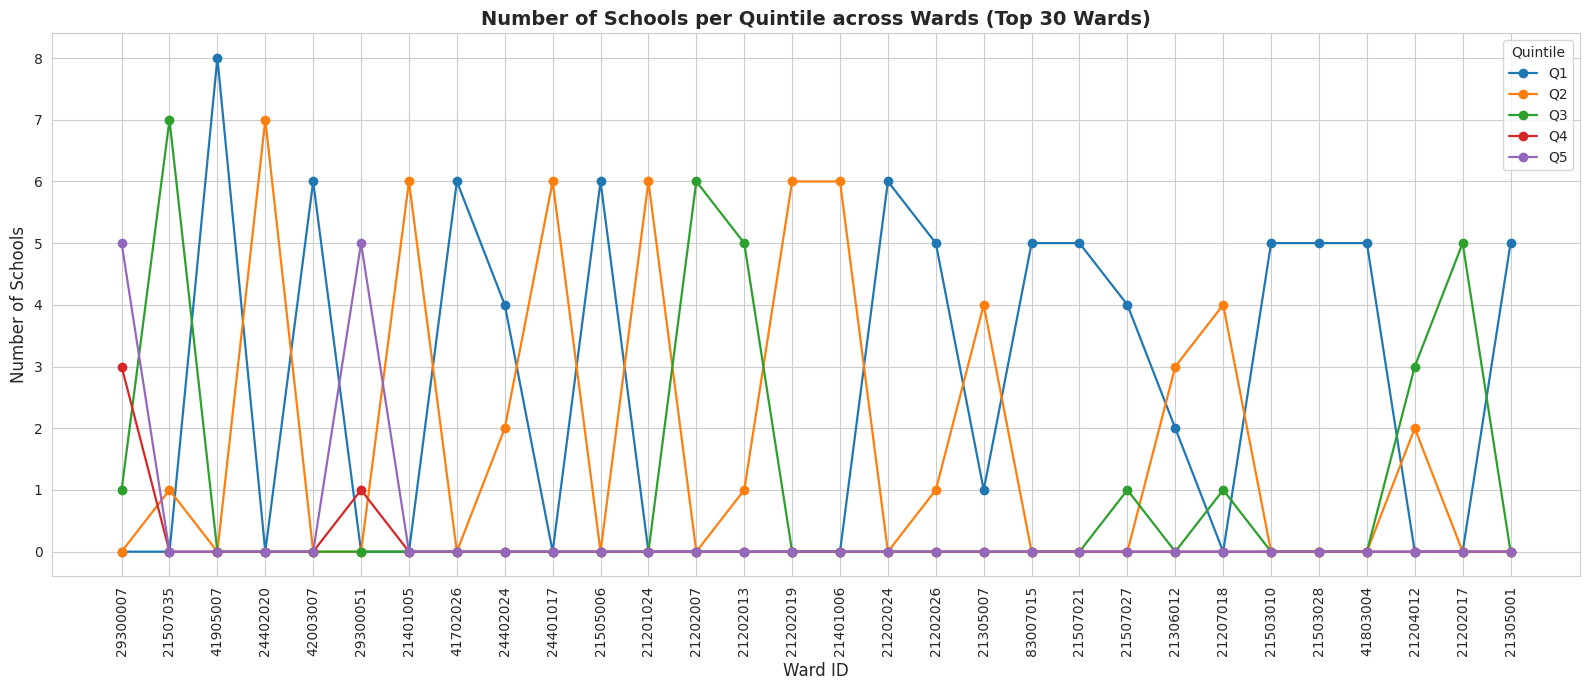

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# ---- 3.1 Aggregate ------------------------------------------------
# Group by ward & quintile, count schools. unstack() puts quintiles
# on columns so each quintile becomes its own line.
ward_quintile = (
    df_clean
    .groupby(['ward_id', 'quintile_clean'])
    .size()
    .unstack(fill_value=0)
)

# OPTIONAL: with hundreds of wards the x-axis gets unreadable.
# Keep the 30 wards with the most schools for a readable line chart.
top_wards = ward_quintile.sum(axis=1).sort_values(ascending=False).head(30).index
ward_quintile_top = ward_quintile.loc[top_wards]

# ---- 3.2 Plot -----------------------------------------------------
plt.figure(figsize=(16, 7))
sns.set_style("whitegrid")

for quintile in ['Q1','Q2','Q3','Q4','Q5']:
    if quintile in ward_quintile_top.columns:
        plt.plot(
            ward_quintile_top.index,
            ward_quintile_top[quintile],
            marker='o',
            linewidth=1.6,
            label=quintile
        )

plt.title("Number of Schools per Quintile across Wards (Top 30 Wards)",
          fontsize=14, fontweight='bold')
plt.xlabel("Ward ID", fontsize=12)
plt.ylabel("Number of Schools", fontsize=12)
plt.xticks(rotation=90)
plt.legend(title="Quintile")
plt.tight_layout()
plt.show()

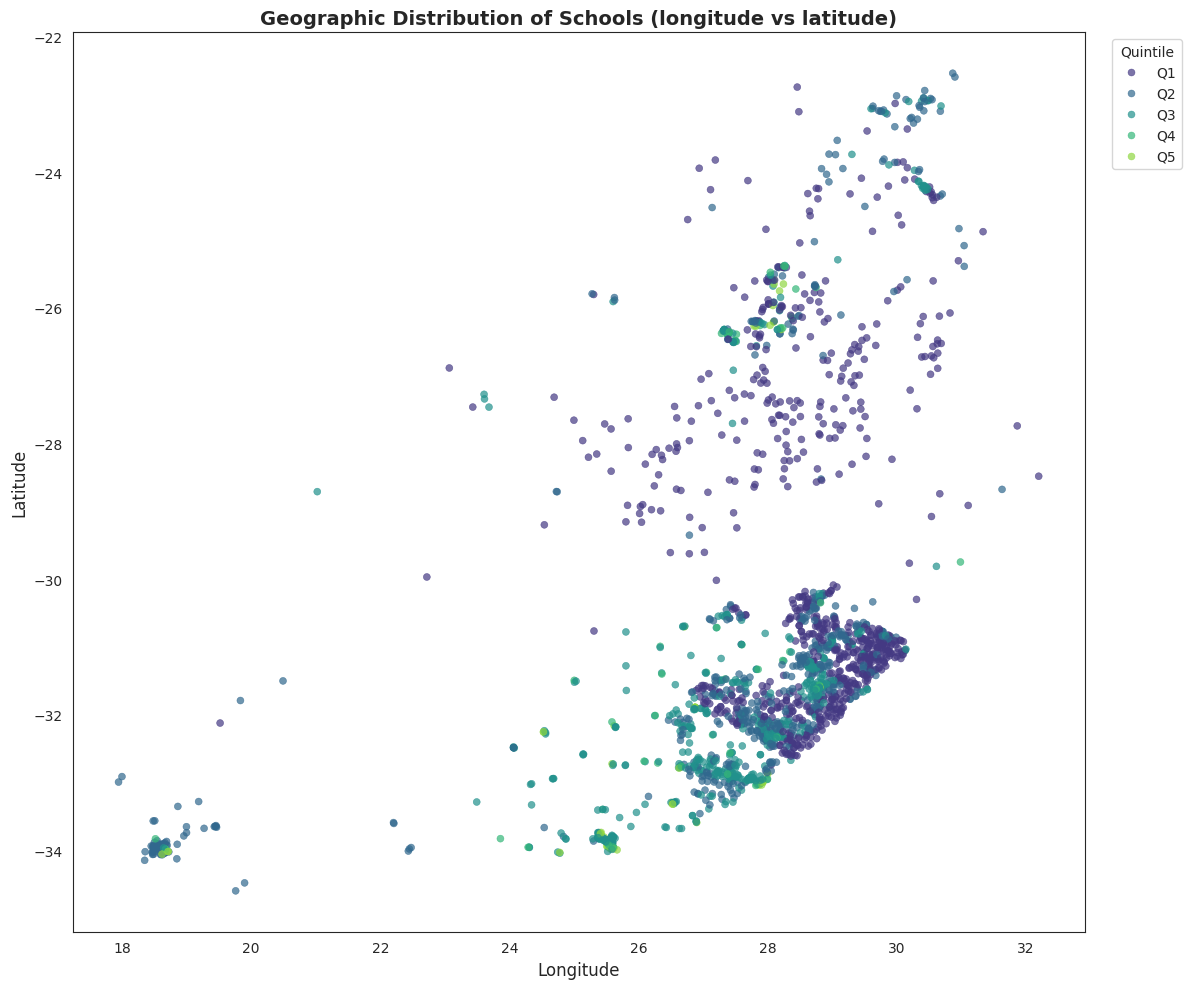

In [8]:
# ---------------------------------------------------------------
# 4. SCATTER PLOT: lat vs long, coloured by quintile
# ---------------------------------------------------------------
plt.figure(figsize=(12, 10))
sns.set_style("white")

# We colour by quintile. Seaborn will raise an error if quintile is
# still `object` with mixed casing; that's why we built quintile_clean.
scatter = sns.scatterplot(
    data=df_clean,
    x='new_long',
    y='new_lat',
    hue='quintile_clean',
    hue_order=['Q1','Q2','Q3','Q4','Q5'],
    palette='viridis',
    s=25,                 # marker size
    alpha=0.7,            # transparency so overlapping dots stay visible
    edgecolor=None
)

plt.title("Geographic Distribution of Schools (longitude vs latitude)",
          fontsize=14, fontweight='bold')
plt.xlabel("Longitude", fontsize=12)
plt.ylabel("Latitude", fontsize=12)
plt.legend(title="Quintile", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

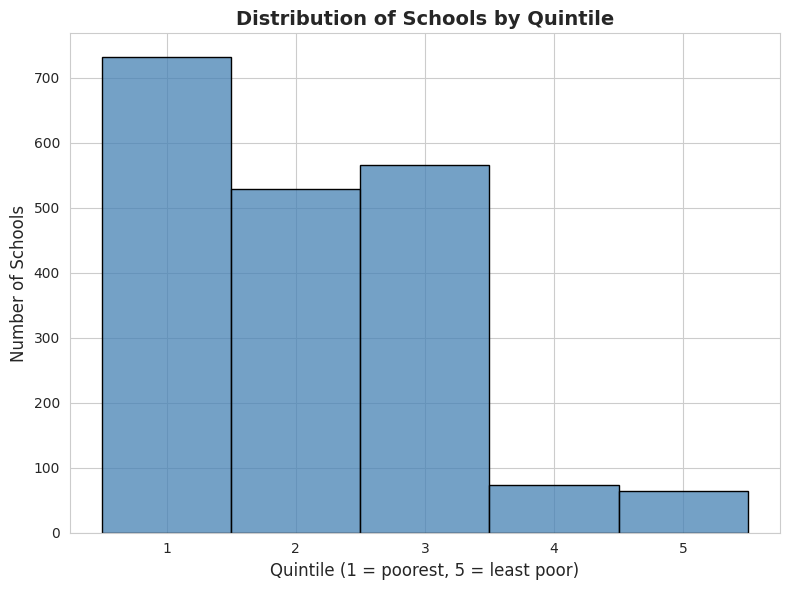

In [9]:
# ---------------------------------------------------------------
# 5. HISTOGRAM: count of schools per quintile
# ---------------------------------------------------------------
plt.figure(figsize=(8, 6))
sns.set_style("whitegrid")

# A histogram is technically for continuous data, but with 5 discrete
# bins it gives a clean bar-like view. We pass bin edges that exactly
# match the 5 quintile codes by converting them to integers 1..5.
quintile_int = df_clean['quintile_clean'].str.replace('Q', '').astype(int)

sns.histplot(
    quintile_int,
    bins=[0.5, 1.5, 2.5, 3.5, 4.5, 5.5],
    kde=False,
    color='steelblue',
    edgecolor='black'
)

plt.title("Distribution of Schools by Quintile",
          fontsize=14, fontweight='bold')
plt.xlabel("Quintile (1 = poorest, 5 = least poor)", fontsize=12)
plt.ylabel("Number of Schools", fontsize=12)
plt.xticks([1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()